**Assignment 1 — Task 2: Exploratory Data Analysis & Data Preparation**

---

*1. Introduction*

In [1]:
# ── Library Imports ────────────────────────────────────────────────────────────
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from PIL import Image, ImageStat
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import image_dataset_from_directory

sns.set_style('whitegrid')
print(f"TensorFlow version : {tf.__version__}")
print("Libraries loaded   : OK")

TensorFlow version : 2.10.0
Libraries loaded   : OK


In [2]:
# ── Dataset path configuration ────────────────────────────────────────────────
DATASET_PATH = './dataset'
TRAIN_DIR = os.path.join(DATASET_PATH, 'Training Data', 'Training Data')
VAL_DIR   = os.path.join(DATASET_PATH, 'Validation Data', 'Validation Data')
TEST_DIR  = os.path.join(DATASET_PATH, 'Testing Data', 'Testing Data')
IMG_SIZE     = (224, 224)
BATCH_SIZE   = 32
SEED         = 42

CLASSES = sorted(os.listdir(TRAIN_DIR))
N_CLASSES = len(CLASSES)
print(f"Classes ({N_CLASSES}): {CLASSES}")

Classes (15): ['Beetle', 'Butterfly', 'Cat', 'Cow', 'Dog', 'Elephant', 'Gorilla', 'Hippo', 'Lizard', 'Monkey', 'Mouse', 'Panda', 'Spider', 'Tiger', 'Zebra']


---
**2. Exploratory Data Analysis (EDA)**

*2.1 Class Distribution Analysis*

In [3]:
# ── Count images per split ────────────────────────────────────────────────────
def count_per_class(root, classes):
    return {
        cls: len([f for f in os.listdir(os.path.join(root, cls))
                  if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
        for cls in classes if os.path.isdir(os.path.join(root, cls))
    }

train_counts = count_per_class(TRAIN_DIR, CLASSES)
val_counts   = count_per_class(VAL_DIR,   CLASSES)
test_counts  = count_per_class(TEST_DIR,  CLASSES)

dist_df = pd.DataFrame({
    'Class' : CLASSES,
    'Train' : [train_counts[c] for c in CLASSES],
    'Val'   : [val_counts.get(c, 0) for c in CLASSES],
    'Test'  : [test_counts.get(c, 0) for c in CLASSES],
})
dist_df['Total'] = dist_df[['Train','Val','Test']].sum(axis=1)

print("=" * 55)
print("IMAGE COUNT PER CLASS")
print("=" * 55)
print(dist_df.to_string(index=False))
print(f"\nOverall total images : {dist_df['Total'].sum()}")
print(f"Mean per class       : {dist_df['Train'].mean():.1f}")
print(f"Std per class        : {dist_df['Train'].std():.1f}")
print(f"Min per class        : {dist_df['Train'].min()}")
print(f"Max per class        : {dist_df['Train'].max()}")

IMAGE COUNT PER CLASS
    Class  Train  Val  Test  Total
   Beetle   2000  200   100   2300
Butterfly   2000  200   100   2300
      Cat   2000  100   394   2494
      Cow   2000  100   177   2277
      Dog   2000  100    88   2188
 Elephant   2000  100   306   2406
  Gorilla   2000  100    30   2130
    Hippo   2000  100    57   2157
   Lizard   2000  200   100   2300
   Monkey   2000  100   184   2284
    Mouse   2000  200   100   2300
    Panda   2000  100   237   2337
   Spider   2000  200   100   2300
    Tiger   2000  100   164   2264
    Zebra   2000  100   270   2370

Overall total images : 34407
Mean per class       : 2000.0
Std per class        : 0.0
Min per class        : 2000
Max per class        : 2000


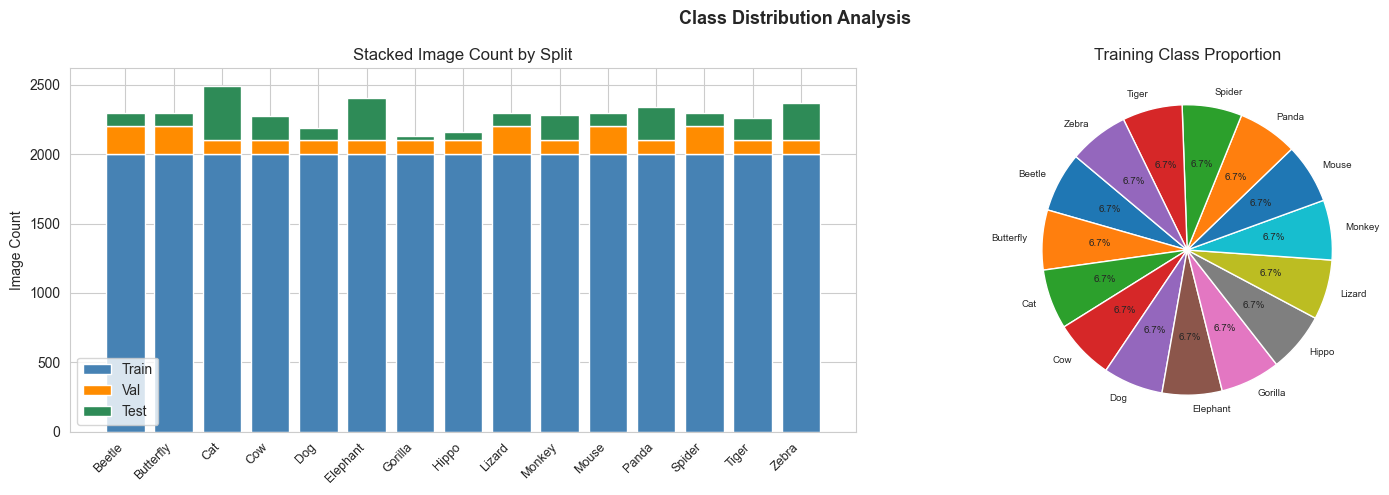


Class imbalance ratio (max/min train): 1.00
✓  Class distribution is reasonably balanced.


In [4]:
# ── Class distribution bar chart ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Stacked bar — all splits
x = np.arange(N_CLASSES)
axes[0].bar(x, dist_df['Train'], label='Train', color='steelblue')
axes[0].bar(x, dist_df['Val'],   bottom=dist_df['Train'], label='Val', color='darkorange')
axes[0].bar(x, dist_df['Test'],  bottom=dist_df['Train']+dist_df['Val'], label='Test', color='seagreen')
axes[0].set_xticks(x)
axes[0].set_xticklabels(CLASSES, rotation=45, ha='right', fontsize=9)
axes[0].set_ylabel('Image Count')
axes[0].set_title('Stacked Image Count by Split')
axes[0].legend()

# Pie chart — class proportions (train only)
axes[1].pie(dist_df['Train'], labels=CLASSES, autopct='%1.1f%%',
            startangle=140, textprops={'fontsize': 7})
axes[1].set_title('Training Class Proportion')

plt.suptitle('Class Distribution Analysis', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_class_distribution.png', dpi=150)
plt.show()

# ── Imbalance ratio ───────────────────────────────────────────────────────────
imbalance_ratio = dist_df['Train'].max() / dist_df['Train'].min()
print(f"\nClass imbalance ratio (max/min train): {imbalance_ratio:.2f}")
if imbalance_ratio > 3:
    print("⚠  Significant class imbalance detected — will apply class weighting.")
else:
    print("✓  Class distribution is reasonably balanced.")

*2.2 Image Dimension & Aspect Ratio Analysis*

In [5]:
# ── Sample image dimension statistics (max 50 per class for speed) ────────────
widths, heights, aspects = [], [], []
SAMPLE_N = 50

for cls in CLASSES:
    folder = os.path.join(TRAIN_DIR, cls)
    imgs = [f for f in os.listdir(folder)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))][:SAMPLE_N]
    for fn in imgs:
        try:
            with Image.open(os.path.join(folder, fn)) as im:
                w, h = im.size
                widths.append(w)
                heights.append(h)
                aspects.append(w / h)
        except Exception:
            pass

print(f"Sampled images       : {len(widths)}")
print(f"Width  — min:{min(widths):4d}  max:{max(widths):4d}  mean:{np.mean(widths):.0f}")
print(f"Height — min:{min(heights):4d}  max:{max(heights):4d}  mean:{np.mean(heights):.0f}")
print(f"Aspect ratio — min:{min(aspects):.2f}  max:{max(aspects):.2f}  mean:{np.mean(aspects):.2f}")

Sampled images       : 750
Width  — min: 256  max: 256  mean:256
Height — min: 256  max: 256  mean:256
Aspect ratio — min:1.00  max:1.00  mean:1.00


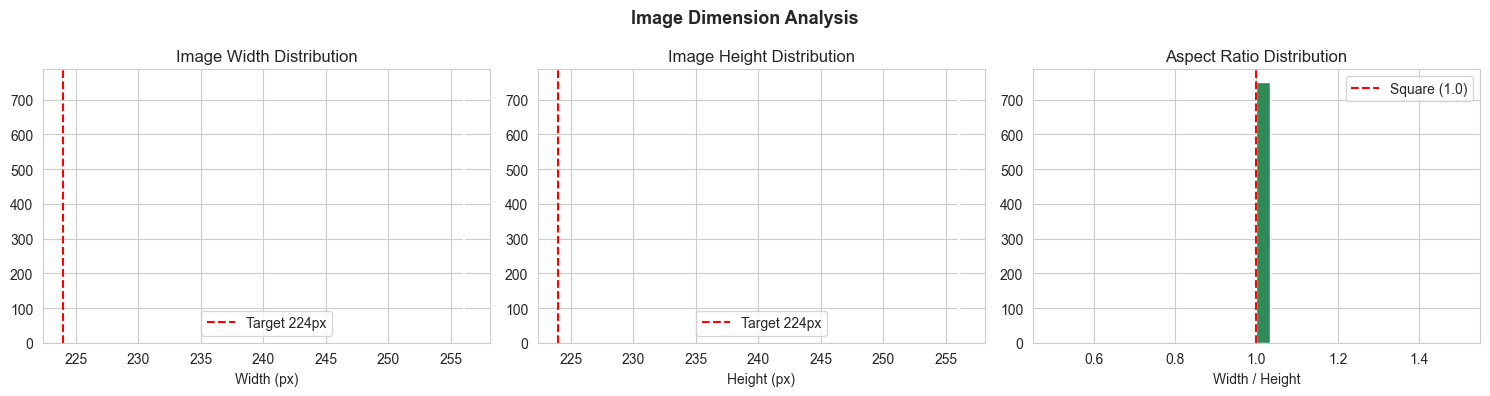

Insight: All images will be resized to 224×224 during preprocessing to standardise input dimensions.


In [6]:
# ── Dimension distribution plots ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(widths,   bins=30, color='steelblue', edgecolor='white')
axes[0].axvline(224, color='red', linestyle='--', label='Target 224px')
axes[0].set_title('Image Width Distribution')
axes[0].set_xlabel('Width (px)')
axes[0].legend()

axes[1].hist(heights,  bins=30, color='darkorange', edgecolor='white')
axes[1].axvline(224, color='red', linestyle='--', label='Target 224px')
axes[1].set_title('Image Height Distribution')
axes[1].set_xlabel('Height (px)')
axes[1].legend()

axes[2].hist(aspects,  bins=30, color='seagreen', edgecolor='white')
axes[2].axvline(1.0, color='red', linestyle='--', label='Square (1.0)')
axes[2].set_title('Aspect Ratio Distribution')
axes[2].set_xlabel('Width / Height')
axes[2].legend()

plt.suptitle('Image Dimension Analysis', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_dimensions.png', dpi=150)
plt.show()
print("Insight: All images will be resized to 224×224 during preprocessing to standardise input dimensions.")

*2.3 Pixel Intensity & Colour Channel Analysis*

In [7]:
# ── Per-channel mean & std across sampled images ──────────────────────────────
r_means, g_means, b_means = [], [], []
r_stds,  g_stds,  b_stds  = [], [], []
STAT_SAMPLE = 20   # images per class

for cls in CLASSES:
    folder = os.path.join(TRAIN_DIR, cls)
    imgs = [f for f in os.listdir(folder)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))][:STAT_SAMPLE]
    for fn in imgs:
        try:
            im = Image.open(os.path.join(folder, fn)).convert('RGB').resize((64, 64))
            arr = np.array(im, dtype=np.float32) / 255.0
            r_means.append(arr[:,:,0].mean())
            g_means.append(arr[:,:,1].mean())
            b_means.append(arr[:,:,2].mean())
            r_stds.append(arr[:,:,0].std())
            g_stds.append(arr[:,:,1].std())
            b_stds.append(arr[:,:,2].std())
        except Exception:
            pass

channel_df = pd.DataFrame({
    'Channel' : ['Red', 'Green', 'Blue'],
    'Mean'    : [np.mean(r_means), np.mean(g_means), np.mean(b_means)],
    'Std'     : [np.mean(r_stds),  np.mean(g_stds),  np.mean(b_stds)],
})
print(channel_df.to_string(index=False))
print("\nThese values will be used for channel-wise normalisation.")

Channel     Mean      Std
    Red 0.545329 0.210514
  Green 0.528999 0.209081
   Blue 0.459807 0.212102

These values will be used for channel-wise normalisation.


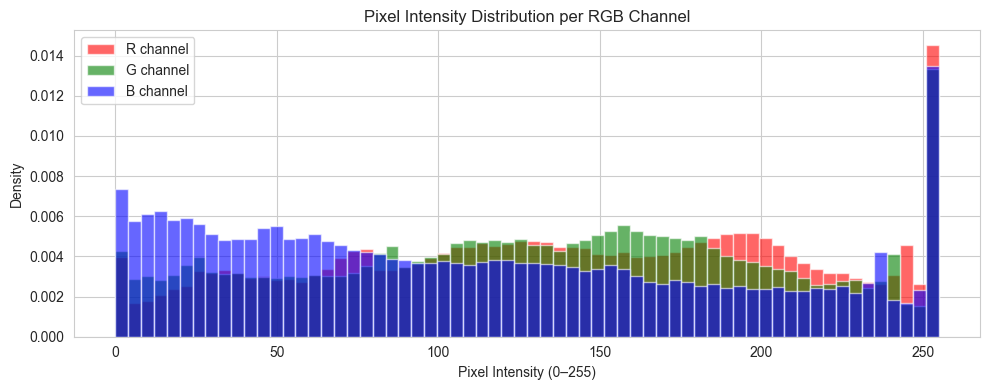

In [8]:
# ── Pixel intensity histogram per channel ─────────────────────────────────────
# Sample one image per class for the histogram
fig, ax = plt.subplots(figsize=(10, 4))
colors = {'R': 'red', 'G': 'green', 'B': 'blue'}

all_pixels = {ch: [] for ch in ['R','G','B']}
for cls in CLASSES[:5]:   # first 5 classes to keep memory manageable
    folder = os.path.join(TRAIN_DIR, cls)
    imgs = [f for f in os.listdir(folder)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))][:10]
    for fn in imgs:
        try:
            arr = np.array(Image.open(os.path.join(folder, fn)).convert('RGB').resize((64,64)))
            all_pixels['R'].extend(arr[:,:,0].flatten())
            all_pixels['G'].extend(arr[:,:,1].flatten())
            all_pixels['B'].extend(arr[:,:,2].flatten())
        except Exception:
            pass

for ch, col in colors.items():
    ax.hist(all_pixels[ch], bins=64, alpha=0.6, color=col, label=f'{ch} channel', density=True)

ax.set_xlabel('Pixel Intensity (0–255)')
ax.set_ylabel('Density')
ax.set_title('Pixel Intensity Distribution per RGB Channel')
ax.legend()
plt.tight_layout()
plt.savefig('eda_pixel_histogram.png', dpi=150)
plt.show()

*2.4 Noise & Corruption Detection*

In [9]:
# ── Scan for corrupted / unreadable images ────────────────────────────────────
corrupt_files = []
too_small_files = []
MIN_DIM = 32   # minimum acceptable dimension (px)

for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    split_name = os.path.basename(split_dir)
    for cls in CLASSES:
        folder = os.path.join(split_dir, cls)
        if not os.path.isdir(folder):
            continue
        for fn in os.listdir(folder):
            if not fn.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue
            fpath = os.path.join(folder, fn)
            try:
                with Image.open(fpath) as im:
                    im.verify()   # detect corruption
                with Image.open(fpath) as im:
                    w, h = im.size
                    if w < MIN_DIM or h < MIN_DIM:
                        too_small_files.append(fpath)
            except Exception as e:
                corrupt_files.append((fpath, str(e)))

print(f"Corrupted images   : {len(corrupt_files)}")
print(f"Too-small images   : {len(too_small_files)}  (< {MIN_DIM}px on any side)")
if corrupt_files:
    print("\nCorrupted files:")
    for f, err in corrupt_files[:5]:
        print(f"  {f} — {err}")
else:
    print("✓  No corrupted images detected.")

Corrupted images   : 0
Too-small images   : 0  (< 32px on any side)
✓  No corrupted images detected.


In [10]:
from scipy import ndimage

NOISE_SAMPLE_N = 40   # images sampled per class — keeps runtime reasonable

def laplacian_variance(gray_arr):
    """Sharpness proxy. Low variance of the Laplacian = flat/blurred image
    (motion blur, low resolution, heavy denoising)."""
    lap = ndimage.laplace(gray_arr.astype(np.float64))
    return lap.var()

def estimate_gaussian_noise(gray_arr):
    H, W = gray_arr.shape
    M = np.array([[1, -2, 1],
                  [-2, 4, -2],
                  [1, -2, 1]], dtype=np.float64)
    conv = ndimage.convolve(gray_arr.astype(np.float64), M, mode='mirror')
    sigma = np.sqrt(np.pi / 2) * np.sum(np.abs(conv)) / (6 * (W - 2) * (H - 2))
    return sigma

def salt_pepper_ratio(gray_arr, low=5, high=250):
    n_extreme = np.sum((gray_arr <= low) | (gray_arr >= high))
    return n_extreme / gray_arr.size

def blockiness_score(gray_arr, block=8):
    h, w = gray_arr.shape
    h -= h % block
    w -= w % block
    arr = gray_arr[:h, :w].astype(np.float64)
    if w < 2 * block:
        return np.nan
    boundary = np.abs(np.diff(arr[:, block - 1::block], axis=1)).mean()
    within = np.abs(np.diff(arr, axis=1)).mean()
    return boundary / (within + 1e-6)

noise_records = []
for cls in CLASSES:
    folder = os.path.join(TRAIN_DIR, cls)
    imgs = [f for f in os.listdir(folder)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))][:NOISE_SAMPLE_N]
    for fn in imgs:
        fpath = os.path.join(folder, fn)
        try:
            with Image.open(fpath) as im:
                gray = np.array(im.convert('L').resize((256, 256)))
            noise_records.append({
                'class'          : cls,
                'file'           : fn,
                'sharpness'      : laplacian_variance(gray),
                'gaussian_sigma' : estimate_gaussian_noise(gray),
                'sp_ratio'       : salt_pepper_ratio(gray),
                'blockiness'     : blockiness_score(gray),
                'mean_brightness': gray.mean(),
            })
        except Exception:
            pass

noise_df = pd.DataFrame(noise_records)
print(f"Scored {len(noise_df)} sampled images across {N_CLASSES} classes for visual noise.")
noise_df[['sharpness', 'gaussian_sigma', 'sp_ratio', 'blockiness', 'mean_brightness']].describe()

Scored 600 sampled images across 15 classes for visual noise.


,sharpness,gaussian_sigma,sp_ratio,blockiness,mean_brightness
count,600.000000,600.000000,600.000000,600.000000,600.000000
mean,1006.444953,1.990905,0.087560,3.480564,133.227507
std,1209.973884,1.726033,0.190338,1.025486,44.211174
min,9.362762,0.141236,0.000000,1.356757,19.781097
25%,295.541626,0.921327,0.000580,2.661721,103.656002
50%,600.183777,1.505608,0.006874,3.359772,126.802200
75%,1346.536736,2.530477,0.052345,4.133778,153.655293
max,9397.563171,14.550153,0.888809,6.318393,247.107803


In [11]:
# ── Flag likely-noisy images using data-driven thresholds ────────────────────
BLUR_THRESH   = noise_df['sharpness'].quantile(0.05)   # bottom 5% sharpness -> likely blurred
SP_THRESH     = 0.02                                    # >2% extreme pixels -> possible salt & pepper
DARK_THRESH   = 25                                      # mean brightness below -> underexposed
BRIGHT_THRESH = 230                                     # mean brightness above -> overexposed
BLOCK_THRESH  = noise_df['blockiness'].quantile(0.95)   # top 5% blockiness -> compression artifacts

noise_df['flag_blur']         = noise_df['sharpness'] < BLUR_THRESH
noise_df['flag_salt_pepper']  = noise_df['sp_ratio'] > SP_THRESH
noise_df['flag_underexposed'] = noise_df['mean_brightness'] < DARK_THRESH
noise_df['flag_overexposed']  = noise_df['mean_brightness'] > BRIGHT_THRESH
noise_df['flag_blocky']       = noise_df['blockiness'] > BLOCK_THRESH

flag_summary = pd.DataFrame({
    'Noise Type'                          : ['Likely Blurred / Motion Blur', 'Possible Salt-and-Pepper',
                                               'Underexposed', 'Overexposed', 'Heavy Compression Blockiness'],
    'Sampled Images Flagged'              : [noise_df['flag_blur'].sum(), noise_df['flag_salt_pepper'].sum(),
                                               noise_df['flag_underexposed'].sum(), noise_df['flag_overexposed'].sum(),
                                               noise_df['flag_blocky'].sum()],
    '% of Sample'                         : [noise_df['flag_blur'].mean() * 100, noise_df['flag_salt_pepper'].mean() * 100,
                                               noise_df['flag_underexposed'].mean() * 100, noise_df['flag_overexposed'].mean() * 100,
                                               noise_df['flag_blocky'].mean() * 100],
})
print(f"Total sampled images: {len(noise_df)}\n")
print(flag_summary.to_string(index=False, float_format=lambda x: f'{x:.1f}'))

# Per-class breakdown (useful to spot whether noise concentrates in specific classes)
per_class_noise = noise_df.groupby('class')[['flag_blur', 'flag_salt_pepper',
                                              'flag_underexposed', 'flag_overexposed', 'flag_blocky']].sum()
print("\nPer-class flagged counts:")
print(per_class_noise.to_string())

Total sampled images: 600

                  Noise Type  Sampled Images Flagged  % of Sample
Likely Blurred / Motion Blur                      30          5.0
    Possible Salt-and-Pepper                     226         37.7
                Underexposed                       1          0.2
                 Overexposed                      23          3.8
Heavy Compression Blockiness                      30          5.0

Per-class flagged counts:
           flag_blur  flag_salt_pepper  flag_underexposed  flag_overexposed  flag_blocky
class                                                                                   
Beetle             0                12                  0                 2            2
Butterfly          0                14                  0                 0            0
Cat                0                27                  0                 1            2
Cow                0                11                  0                 0            0
Dog             

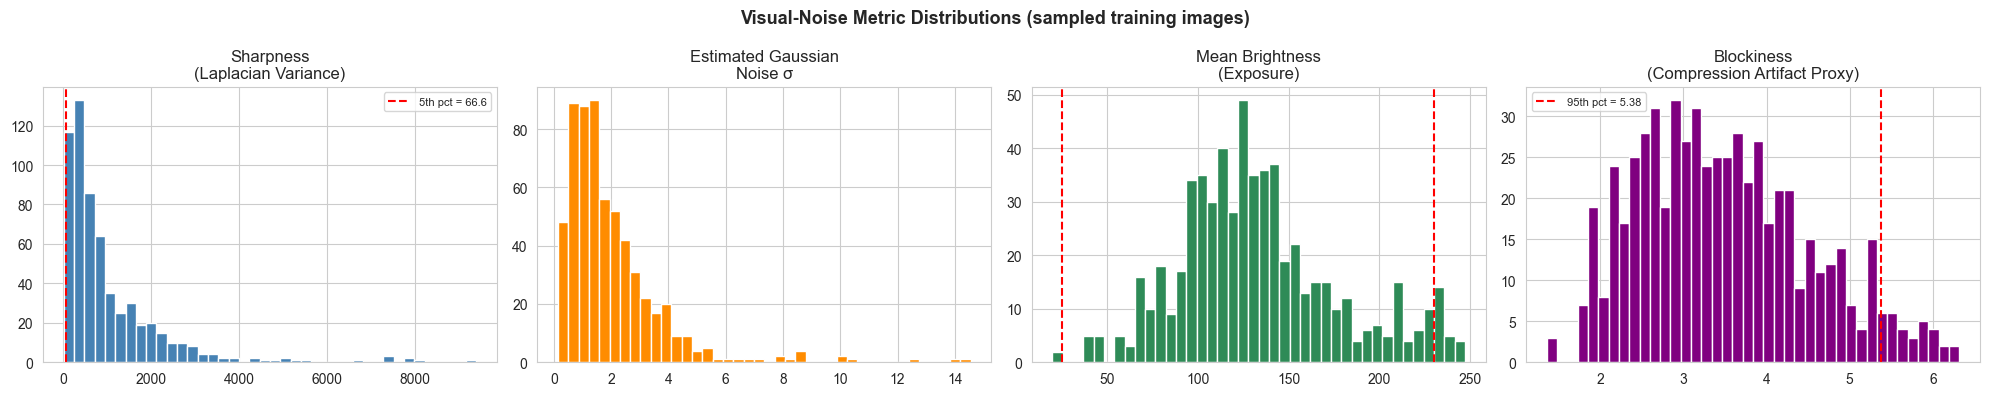

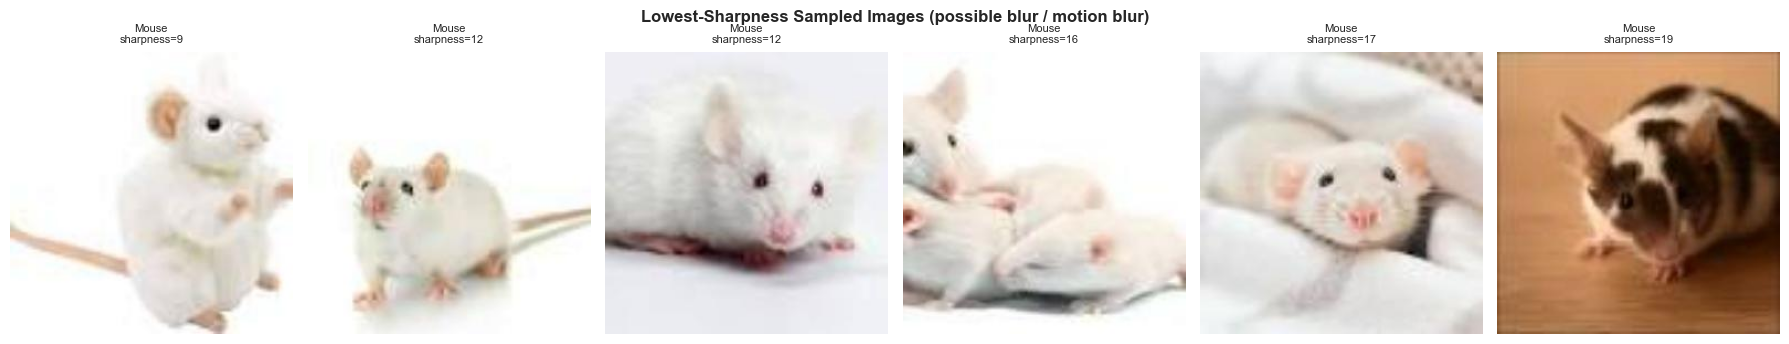

In [12]:
# ── Visualise noise-metric distributions + worst offenders ───────────────────
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].hist(noise_df['sharpness'], bins=40, color='steelblue', edgecolor='white')
axes[0].axvline(BLUR_THRESH, color='red', linestyle='--', label=f'5th pct = {BLUR_THRESH:.1f}')
axes[0].set_title('Sharpness\n(Laplacian Variance)'); axes[0].legend(fontsize=8)

axes[1].hist(noise_df['gaussian_sigma'], bins=40, color='darkorange', edgecolor='white')
axes[1].set_title('Estimated Gaussian\nNoise σ')

axes[2].hist(noise_df['mean_brightness'], bins=40, color='seagreen', edgecolor='white')
axes[2].axvline(DARK_THRESH, color='red', linestyle='--')
axes[2].axvline(BRIGHT_THRESH, color='red', linestyle='--')
axes[2].set_title('Mean Brightness\n(Exposure)')

axes[3].hist(noise_df['blockiness'].dropna(), bins=40, color='purple', edgecolor='white')
axes[3].axvline(BLOCK_THRESH, color='red', linestyle='--', label=f'95th pct = {BLOCK_THRESH:.2f}')
axes[3].set_title('Blockiness\n(Compression Artifact Proxy)'); axes[3].legend(fontsize=8)

plt.suptitle('Visual-Noise Metric Distributions (sampled training images)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_noise_metrics.png', dpi=150)
plt.show()

# Show the 6 lowest-sharpness sampled images as concrete evidence of blur
worst = noise_df.nsmallest(6, 'sharpness')
fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
for ax, (_, row) in zip(axes, worst.iterrows()):
    img = Image.open(os.path.join(TRAIN_DIR, row['class'], row['file'])).convert('RGB')
    ax.imshow(img)
    ax.set_title(f"{row['class']}\nsharpness={row['sharpness']:.0f}", fontsize=8)
    ax.axis('off')
plt.suptitle('Lowest-Sharpness Sampled Images (possible blur / motion blur)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_blurriest_samples.png', dpi=150)
plt.show()

*2.5 Duplicate / Near-Duplicate Detection*

In [13]:
# ── Detect duplicate images using file-size hashing (fast proxy) ──────────────
from hashlib import md5

hash_map = defaultdict(list)
for cls in CLASSES:
    folder = os.path.join(TRAIN_DIR, cls)
    for fn in os.listdir(folder):
        if not fn.lower().endswith(('.jpg', '.jpeg', '.png')):
            continue
        fpath = os.path.join(folder, fn)
        try:
            with open(fpath, 'rb') as f:
                h = md5(f.read()).hexdigest()
            hash_map[h].append(fpath)
        except Exception:
            pass

duplicates = {h: paths for h, paths in hash_map.items() if len(paths) > 1}
n_dup = sum(len(v) - 1 for v in duplicates.values())

print(f"Duplicate images (exact MD5 match): {n_dup}")
if duplicates:
    print("Sample duplicate groups:")
    for h, paths in list(duplicates.items())[:3]:
        print(f"  {paths}")
else:
    print("✓  No exact duplicate images found.")

Duplicate images (exact MD5 match): 1893
Sample duplicate groups:
  ['./dataset\\Training Data\\Training Data\\Beetle\\Beetle-Train (1022).jpeg', './dataset\\Training Data\\Training Data\\Beetle\\Beetle-Train (338).jpeg']
  ['./dataset\\Training Data\\Training Data\\Beetle\\Beetle-Train (1026).jpeg', './dataset\\Training Data\\Training Data\\Beetle\\Beetle-Train (1480).jpeg', './dataset\\Training Data\\Training Data\\Beetle\\Beetle-Train (932).jpeg']
  ['./dataset\\Training Data\\Training Data\\Beetle\\Beetle-Train (1027).jpeg', './dataset\\Training Data\\Training Data\\Beetle\\Beetle-Train (931).jpeg']


In [14]:
# ── Near-duplicate detection using perceptual (average) hashing ──────────────
HASH_SIZE       = 8     # 8x8 = 64-bit hash
NEAR_DUP_SAMPLE = 150   # images per class — keeps pairwise comparison tractable

def average_hash(img_path, hash_size=HASH_SIZE):
    with Image.open(img_path) as im:
        im = im.convert('L').resize((hash_size, hash_size), Image.LANCZOS)
        pixels = np.asarray(im, dtype=np.float64)
    return (pixels > pixels.mean()).flatten()

def hamming_distance(h1, h2):
    return int(np.count_nonzero(h1 != h2))

phash_map = {}
for cls in CLASSES:
    folder = os.path.join(TRAIN_DIR, cls)
    imgs = [f for f in os.listdir(folder)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))][:NEAR_DUP_SAMPLE]
    for fn in imgs:
        fpath = os.path.join(folder, fn)
        try:
            phash_map[fpath] = average_hash(fpath)
        except Exception:
            pass

print(f"Hashed {len(phash_map)} sampled training images for near-duplicate search.")

Hashed 2250 sampled training images for near-duplicate search.


Near-duplicate pairs found (Hamming ≤ 5): 107
  dist=5  Beetle-Train (1000).jpeg  ~  Beetle-Train (1114).jpeg
  dist=5  Beetle-Train (1002).jpeg  ~  Beetle-Train (1019).jpeg
  dist=3  Beetle-Train (1002).jpeg  ~  Beetle-Train (1093).jpeg
  dist=2  Beetle-Train (1002).jpeg  ~  Beetle-Train (1119).jpeg
  dist=5  Beetle-Train (1015).jpeg  ~  Beetle-Train (1019).jpeg


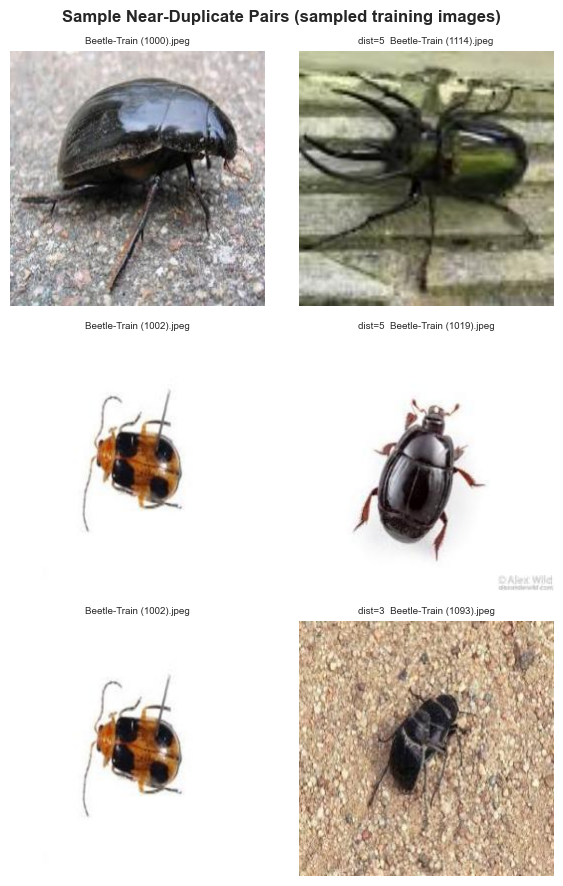

In [15]:
# ── Search for near-duplicate pairs within each class (Hamming distance ≤ 5) ──
NEAR_DUP_THRESHOLD = 5

near_dup_pairs = []
for cls in CLASSES:
    cls_paths = [p for p in phash_map if os.path.basename(os.path.dirname(p)) == cls]
    hashes = [phash_map[p] for p in cls_paths]
    for i in range(len(cls_paths)):
        for j in range(i + 1, len(cls_paths)):
            d = hamming_distance(hashes[i], hashes[j])
            if d <= NEAR_DUP_THRESHOLD:
                near_dup_pairs.append((cls_paths[i], cls_paths[j], d))

print(f"Near-duplicate pairs found (Hamming ≤ {NEAR_DUP_THRESHOLD}): {len(near_dup_pairs)}")
for p1, p2, d in near_dup_pairs[:5]:
    print(f"  dist={d}  {os.path.basename(p1)}  ~  {os.path.basename(p2)}")

if near_dup_pairs:
    n_show = min(3, len(near_dup_pairs))
    fig, axes = plt.subplots(n_show, 2, figsize=(6, 3 * n_show))
    axes = np.atleast_2d(axes)
    for row, (p1, p2, d) in enumerate(near_dup_pairs[:n_show]):
        axes[row][0].imshow(Image.open(p1).convert('RGB')); axes[row][0].axis('off')
        axes[row][0].set_title(os.path.basename(p1), fontsize=7)
        axes[row][1].imshow(Image.open(p2).convert('RGB')); axes[row][1].axis('off')
        axes[row][1].set_title(f"dist={d}  {os.path.basename(p2)}", fontsize=7)
    plt.suptitle('Sample Near-Duplicate Pairs (sampled training images)', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('eda_near_duplicates.png', dpi=150)
    plt.show()
else:
    print("No near-duplicate pairs found at this threshold within the sampled images.")

In [16]:
# ── Cross-split leakage check: same image in Train AND Val/Test ─────────────
from hashlib import md5

def hash_folder(root, classes, sample_n=None):
    out = {}
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            continue
        files = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        if sample_n:
            files = files[:sample_n]
        for fn in files:
            fpath = os.path.join(folder, fn)
            try:
                with open(fpath, 'rb') as fh:
                    out[md5(fh.read()).hexdigest()] = fpath
            except Exception:
                pass
    return out

train_hashes = hash_folder(TRAIN_DIR, CLASSES)
val_hashes   = hash_folder(VAL_DIR,   CLASSES)
test_hashes  = hash_folder(TEST_DIR,  CLASSES)

train_val_leak  = set(train_hashes) & set(val_hashes)
train_test_leak = set(train_hashes) & set(test_hashes)
val_test_leak   = set(val_hashes)   & set(test_hashes)

print(f"Exact-duplicate leakage — Train ↔ Val  : {len(train_val_leak)} image(s)")
print(f"Exact-duplicate leakage — Train ↔ Test : {len(train_test_leak)} image(s)")
print(f"Exact-duplicate leakage — Val   ↔ Test : {len(val_test_leak)} image(s)")

if train_val_leak or train_test_leak or val_test_leak:
    print("\n⚠ Leakage detected. The affected files inflate validation/test metrics")
    print("  and should be removed from whichever split is NOT the primary one")
    print("  (typically keep in Test/Val, drop from Train) before final training.")
    leaked_paths = [train_hashes[h] for h in (train_val_leak | train_test_leak)]
    print(f"\nExample leaked file path(s): {leaked_paths[:3]}")
else:
    print("\n✓ No exact byte-identical leakage found between Train / Val / Test splits.")
print("\nNote: this check is exact-hash based (fast, zero false positives).")
print("Combine with the near-duplicate scan above if you also want to catch")
print("resized/re-compressed leaked copies across splits.")

Exact-duplicate leakage — Train ↔ Val  : 108 image(s)
Exact-duplicate leakage — Train ↔ Test : 18 image(s)
Exact-duplicate leakage — Val   ↔ Test : 13 image(s)

⚠ Leakage detected. The affected files inflate validation/test metrics
  and should be removed from whichever split is NOT the primary one
  (typically keep in Test/Val, drop from Train) before final training.

Example leaked file path(s): ['./dataset\\Training Data\\Training Data\\Spider\\Spider-Train (460).jpeg', './dataset\\Training Data\\Training Data\\Spider\\Spider-Train (683).jpeg', './dataset\\Training Data\\Training Data\\Cat\\Cat-Train (1857).jpeg']

Note: this check is exact-hash based (fast, zero false positives).
Combine with the near-duplicate scan above if you also want to catch
resized/re-compressed leaked copies across splits.


*2.6 Sample Grid Visualisation*

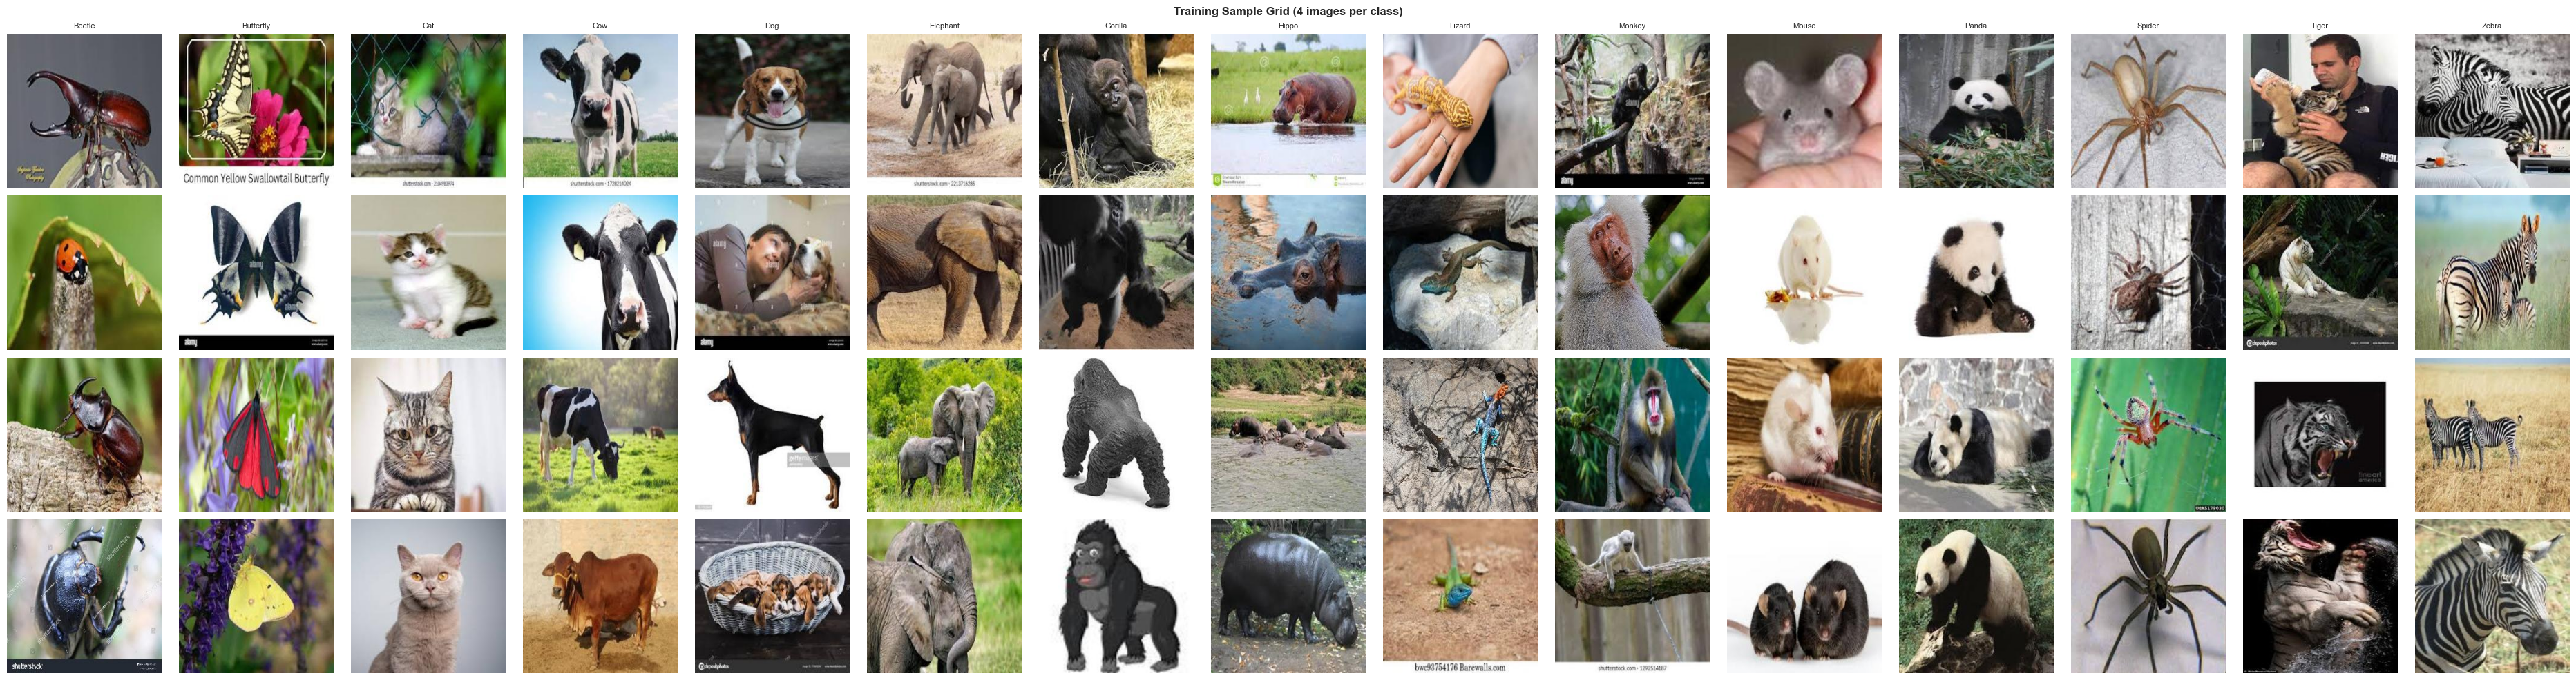

In [17]:
# ── Display a 4×(N_CLASSES) grid of training samples ──────────────────────────
COLS = N_CLASSES
ROWS = 4
fig, axes = plt.subplots(ROWS, COLS, figsize=(COLS * 2.5, ROWS * 2.5))

for col_idx, cls in enumerate(CLASSES):
    folder = os.path.join(TRAIN_DIR, cls)
    imgs = [f for f in os.listdir(folder)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    chosen = np.random.choice(imgs, size=min(ROWS, len(imgs)), replace=False)
    for row_idx, fn in enumerate(chosen):
        img = Image.open(os.path.join(folder, fn)).convert('RGB')
        axes[row_idx][col_idx].imshow(img)
        if row_idx == 0:
            axes[row_idx][col_idx].set_title(cls.capitalize(), fontsize=8)
        axes[row_idx][col_idx].axis('off')
    # Fill empty rows if class has fewer than ROWS images
    for row_idx in range(len(chosen), ROWS):
        axes[row_idx][col_idx].axis('off')

plt.suptitle('Training Sample Grid (4 images per class)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_sample_grid.png', dpi=150)
plt.show()

---
**3. Data Preparation & Preprocessing**

*3.1 Preprocessing Strategy*

In [18]:
# ── Remove confirmed corrupt files ────────────────────────────────────────────
removed = 0
for fpath, _ in corrupt_files:
    try:
        os.remove(fpath)
        removed += 1
    except Exception:
        pass
print(f"Removed {removed} corrupt file(s).")

Removed 0 corrupt file(s).


In [19]:
# ── Data Augmentation pipeline (training set only) ────────────────────────────
train_datagen = ImageDataGenerator(
    rescale           = 1.0 / 255.0,
    rotation_range    = 20,          # random rotation ±20°
    width_shift_range = 0.15,        # horizontal shift
    height_shift_range= 0.15,        # vertical shift
    shear_range       = 0.1,         # shear transformation
    zoom_range        = 0.2,         # random zoom
    horizontal_flip   = True,        # random horizontal flip
    brightness_range  = [0.8, 1.2],  # brightness variation
    fill_mode         = 'nearest'
)

# Validation & Test: only rescale (no augmentation)
val_test_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', seed=SEED, shuffle=True
)
val_gen = val_test_datagen.flow_from_directory(
    VAL_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', seed=SEED, shuffle=False
)
test_gen = val_test_datagen.flow_from_directory(
    TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', seed=SEED, shuffle=False
)

print(f"Train batches : {len(train_gen)}")
print(f"Val   batches : {len(val_gen)}")
print(f"Test  batches : {len(test_gen)}")
print(f"Class indices : {train_gen.class_indices}")

Found 30000 images belonging to 15 classes.
Found 2000 images belonging to 15 classes.
Found 2407 images belonging to 15 classes.
Train batches : 938
Val   batches : 63
Test  batches : 76
Class indices : {'Beetle': 0, 'Butterfly': 1, 'Cat': 2, 'Cow': 3, 'Dog': 4, 'Elephant': 5, 'Gorilla': 6, 'Hippo': 7, 'Lizard': 8, 'Monkey': 9, 'Mouse': 10, 'Panda': 11, 'Spider': 12, 'Tiger': 13, 'Zebra': 14}


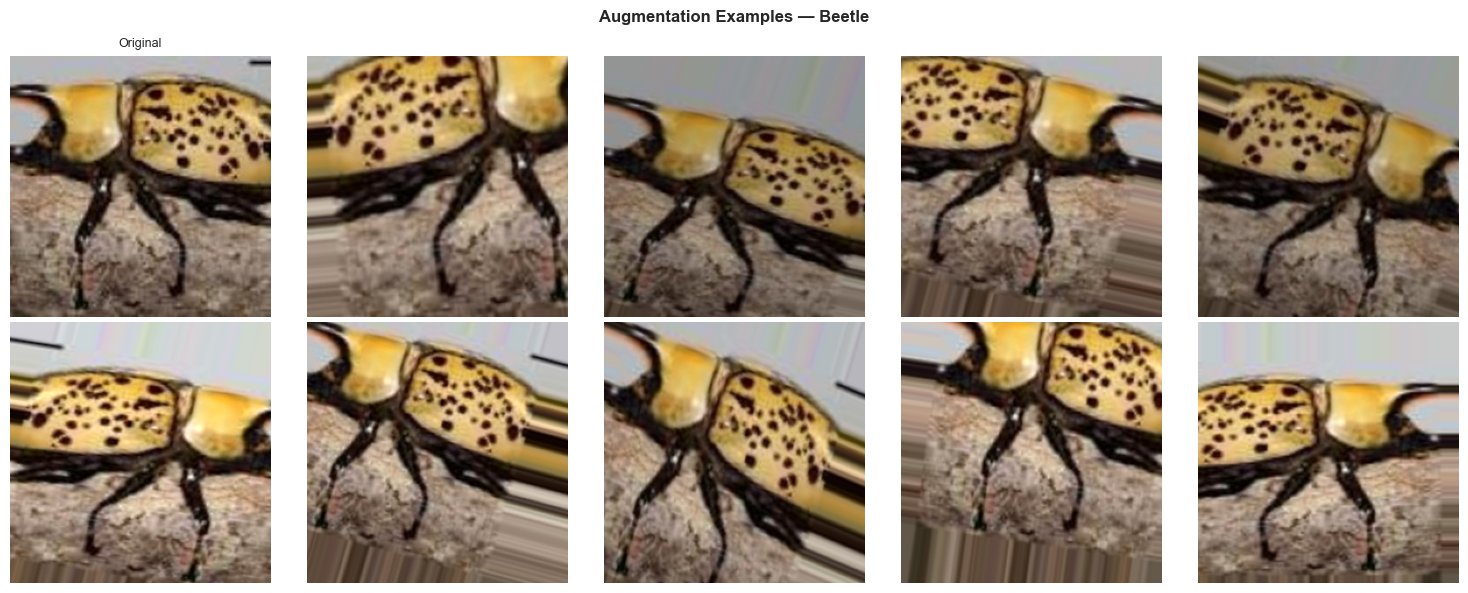

Augmentation applied: rotation, flip, zoom, shift, brightness adjustment.


In [20]:
# ── Visualise augmented samples ───────────────────────────────────────────────
# Pick one sample image and show original + 8 augmentations
sample_class = CLASSES[0]
sample_img_path = os.path.join(TRAIN_DIR, sample_class,
    next(f for f in os.listdir(os.path.join(TRAIN_DIR, sample_class))
         if f.lower().endswith(('.jpg','.jpeg','.png'))))

sample_arr = np.expand_dims(
    np.array(Image.open(sample_img_path).convert('RGB').resize(IMG_SIZE)), 0
)
aug_gen = train_datagen.flow(sample_arr, batch_size=1, seed=SEED)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes[0][0].imshow(np.array(Image.open(sample_img_path).convert('RGB').resize(IMG_SIZE)))
axes[0][0].set_title('Original', fontsize=9)
axes[0][0].axis('off')

all_axes = [axes[r][c] for r in range(2) for c in range(5)]
for ax in all_axes[1:]:
    aug_img = next(aug_gen)[0]
    ax.imshow(aug_img)
    ax.axis('off')

plt.suptitle(f'Augmentation Examples — {sample_class.capitalize()}', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_augmentation_samples.png', dpi=150)
plt.show()
print("Augmentation applied: rotation, flip, zoom, shift, brightness adjustment.")

In [21]:
# ── Compute class weights for imbalanced datasets ─────────────────────────────
from sklearn.utils.class_weight import compute_class_weight

y_train = train_gen.classes
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights_array))
print("Class weights:")
for idx, cls in enumerate(CLASSES):
    print(f"  [{idx}] {cls:20s} → weight = {class_weight_dict[idx]:.4f}")

Class weights:
  [0] Beetle               → weight = 1.0000
  [1] Butterfly            → weight = 1.0000
  [2] Cat                  → weight = 1.0000
  [3] Cow                  → weight = 1.0000
  [4] Dog                  → weight = 1.0000
  [5] Elephant             → weight = 1.0000
  [6] Gorilla              → weight = 1.0000
  [7] Hippo                → weight = 1.0000
  [8] Lizard               → weight = 1.0000
  [9] Monkey               → weight = 1.0000
  [10] Mouse                → weight = 1.0000
  [11] Panda                → weight = 1.0000
  [12] Spider               → weight = 1.0000
  [13] Tiger                → weight = 1.0000
  [14] Zebra                → weight = 1.0000


In [22]:
# ── Verify a batch shape ──────────────────────────────────────────────────────
x_batch, y_batch = next(train_gen)
print(f"Batch image shape : {x_batch.shape}   (batch, height, width, channels)")
print(f"Batch label shape : {y_batch.shape}   (batch, n_classes)")
print(f"Pixel min/max     : {x_batch.min():.4f} / {x_batch.max():.4f}  (after rescaling)")
print(f"Label example     : {y_batch[0]}")

Batch image shape : (32, 224, 224, 3)   (batch, height, width, channels)
Batch label shape : (32, 15)   (batch, n_classes)
Pixel min/max     : 0.0000 / 1.0000  (after rescaling)
Label example     : [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


---
**4. EDA Summary & Insights**

In [23]:
# ── Save generator config for reuse in Assignment 2 notebooks ─────────────────
import json

config = {
    'DATASET_PATH' : DATASET_PATH,
    'TRAIN_DIR': TRAIN_DIR,
    'VAL_DIR'      : VAL_DIR,
    'TEST_DIR'     : TEST_DIR,
    'IMG_SIZE'     : list(IMG_SIZE),
    'BATCH_SIZE'   : BATCH_SIZE,
    'N_CLASSES'    : N_CLASSES,
    'CLASSES'      : CLASSES,
    'CLASS_WEIGHTS': class_weight_dict,
    'SEED'         : SEED,
}

with open('dataset_config.json', 'w') as fp:
    json.dump(config, fp, indent=2)

print("✓  dataset_config.json saved — import this in A2 notebooks.")

✓  dataset_config.json saved — import this in A2 notebooks.
